# 🛰️ Titan-Edge Digital Twin PoC — HAB & Water-Quality Guard for Desalination Intakes
**Theme:** `06_ecosystem_health_water_quality` | **Layers:** Sentinel-2 (macro) + Planet Tanager (hyperspectral) | **Output:** NDCI hotspot map, clean spectrum comparison, Titan-Edge trigger logs

Pipeline: 1) Theme & AOI → 2) Sentinel-2 NDCI/NDWI → 3) Tanager hyperspectral + clean spectrum → 4) Fusion map → 5) Titan-Edge decision kernel.

In [1]:
%pip install -q pystac-client planetary-computer stackstac rasterio xarray matplotlib geopandas leafmap h5py ipywidgets rioxarray folium branca shapely requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 669.2/669.2 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 106.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 108.6/108.6 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 93.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 57.

## 1️⃣ Theme & AOI Setup
AOI = Gulf of Oman coast near Fujairah (water + coastline). **Replace `INTAKE_LATLON` with the real intake coordinates** of your target plant.

In [2]:
import os, json, warnings
from datetime import datetime, timezone
from urllib.parse import urljoin

import numpy as np
import requests
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import xarray as xr
import rioxarray
import pystac_client, planetary_computer, stackstac
import h5py
import folium
import branca.colormap as bcm
import leafmap.foliumap as leafmap
from shapely.geometry import box

warnings.filterwarnings("ignore")

# ---- Theme / AOI configuration ----
THEME = "06_ecosystem_health_water_quality"
AOI_NAME = "Fujairah - Gulf of Oman (desalination intake zone)"
bbox = [56.30, 25.05, 56.55, 25.25]      # [min lon, min lat, max lon, max lat]
time_range = "2025-02-15/2025-03-15"     # overlaps the Tanager example scenes (Feb-Mar 2025)
CLOUD_MAX = 30                           # % scene cloud cover
UTM_EPSG = 32640                         # UTM zone 40N (covers Fujairah)
INTAKE_LATLON = (25.17, 56.36)           # ILLUSTRATIVE - replace with the real intake location
HAB_THRESHOLD = 0.25                     # NDCI alert threshold (calibrate with ground truth!)

print("Theme:", THEME)
print("AOI  :", AOI_NAME, bbox)
print("Time :", time_range)

Theme: 06_ecosystem_health_water_quality
AOI  : Fujairah - Gulf of Oman (desalination intake zone) [56.3, 25.05, 56.55, 25.25]
Time : 2025-02-15/2025-03-15


## 2️⃣ Sentinel-2 Macro-Sensing Layer
- STAC query on Planetary Computer (`sentinel-2-l2a`)
- **NDCI** = (B05 − B04) / (B05 + B04) → B04 = 665 nm, B05 = 705 nm
- **NDWI** = (B03 − B08) / (B03 + B08) → water delineation (we use NDWI instead of the SCL water class, because bloom pixels are often misclassified as vegetation)
- Bands are loaded at 20 m (B05 native resolution); clouds/shadows are masked with the SCL band.

In [3]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,   # required to read PC data
)

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime=time_range,
    query={"eo:cloud_cover": {"lt": CLOUD_MAX}},
)
s2_items = list(search.item_collection())
print(f"Found {len(s2_items)} Sentinel-2 scenes")
assert len(s2_items) > 0, "No scenes found - widen time_range or raise CLOUD_MAX"
for it in sorted(s2_items, key=lambda i: i.datetime)[:15]:
    print(it.datetime.date(), it.id, f"cloud={it.properties['eo:cloud_cover']:.1f}%")

Found 7 Sentinel-2 scenes
2025-02-21 S2C_MSIL2A_20250221T064931_R020_T40RDP_20250221T133915 cloud=4.5%
2025-02-21 S2C_MSIL2A_20250221T064931_R020_T40RDN_20250221T133915 cloud=17.0%
2025-02-26 S2B_MSIL2A_20250226T064739_R020_T40RDN_20250226T085342 cloud=8.5%
2025-03-03 S2C_MSIL2A_20250303T064821_R020_T40RDP_20250303T121710 cloud=1.9%
2025-03-03 S2C_MSIL2A_20250303T064821_R020_T40RDN_20250303T121710 cloud=1.9%
2025-03-08 S2B_MSIL2A_20250308T064629_R020_T40RDP_20250308T085847 cloud=25.6%
2025-03-08 S2B_MSIL2A_20250308T064629_R020_T40RDN_20250308T085847 cloud=26.0%


In [10]:
# Load only the needed bands (lazy COG reads -> compute once)
# NOTE: epsg must be a projected CRS (meters). Do not use 4326 with resolution=20.
import logging
logging.getLogger("rasterio._env").setLevel(logging.ERROR)
data = stackstac.stack(
    s2_items,
    assets=["B03", "B04", "B05", "B08", "SCL"],
    resolution=20,
    bounds_latlon=bbox,
    epsg=UTM_EPSG,
    dtype="float32",
    fill_value=np.float32("nan"),

    rescale=False,
    chunksize=1024,
).compute()
print(data.dims, data.shape)

('time', 'band', 'y', 'x') (7, 5, 1114, 1266)


In [11]:
def band(name):
    return data.sel(band=name).drop_vars("band")

# Cloud / shadow / cirrus / nodata / saturated / snow mask from SCL
scl = band("SCL")
bad = scl.isin([0, 1, 3, 8, 9, 10, 11])

# DN -> surface reflectance (L2A baseline >= 04.00: scale 1/10000, offset -0.1)
def refl(name):
    return ((band(name) / 10000.0) - 0.1).where(~bad)

def composite(a):
    return a.median("time", skipna=True).reset_coords(drop=True)

r03, r04, r05, r08 = [composite(refl(b)) for b in ["B03", "B04", "B05", "B08"]]

ndwi_da = (r03 - r08) / (r03 + r08 + 1e-6)
water_mask = ndwi_da > 0.0
ndci_da = ((r05 - r04) / (r05 + r04 + 1e-6)).where(water_mask)

ndwi_da = ndwi_da.rio.write_crs(f"EPSG:{UTM_EPSG}")
ndci_da = ndci_da.rio.write_crs(f"EPSG:{UTM_EPSG}")

ndwi_s2 = ndwi_da.values
ndci_s2 = ndci_da.values        # NDCI over WATER pixels only (NaN elsewhere)

def summarize_index(name, arr):
    arr = np.asarray(arr, dtype="float64")
    if np.isfinite(arr).sum() == 0:
        print(f"{name}: no valid pixels\n"); return
    print(f"{name}:")
    print(f"  min   = {np.nanmin(arr):.4f}")
    print(f"  max   = {np.nanmax(arr):.4f}")
    print(f"  mean  = {np.nanmean(arr):.4f}")
    print(f"  std   = {np.nanstd(arr):.4f}\n")

print("Water pixels: %.1f%% of AOI" % (100 * np.isfinite(ndci_s2).mean()))
summarize_index("NDWI (all valid pixels)", ndwi_s2)
summarize_index("NDCI (water pixels)", ndci_s2)

Water pixels: 74.5% of AOI
NDWI (all valid pixels):
  min   = -0.8112
  max   = 0.8302
  mean  = 0.1257
  std   = 0.1868

NDCI (water pixels):
  min   = -1.3142
  max   = 0.7874
  mean  = 0.0034
  std   = 0.0618



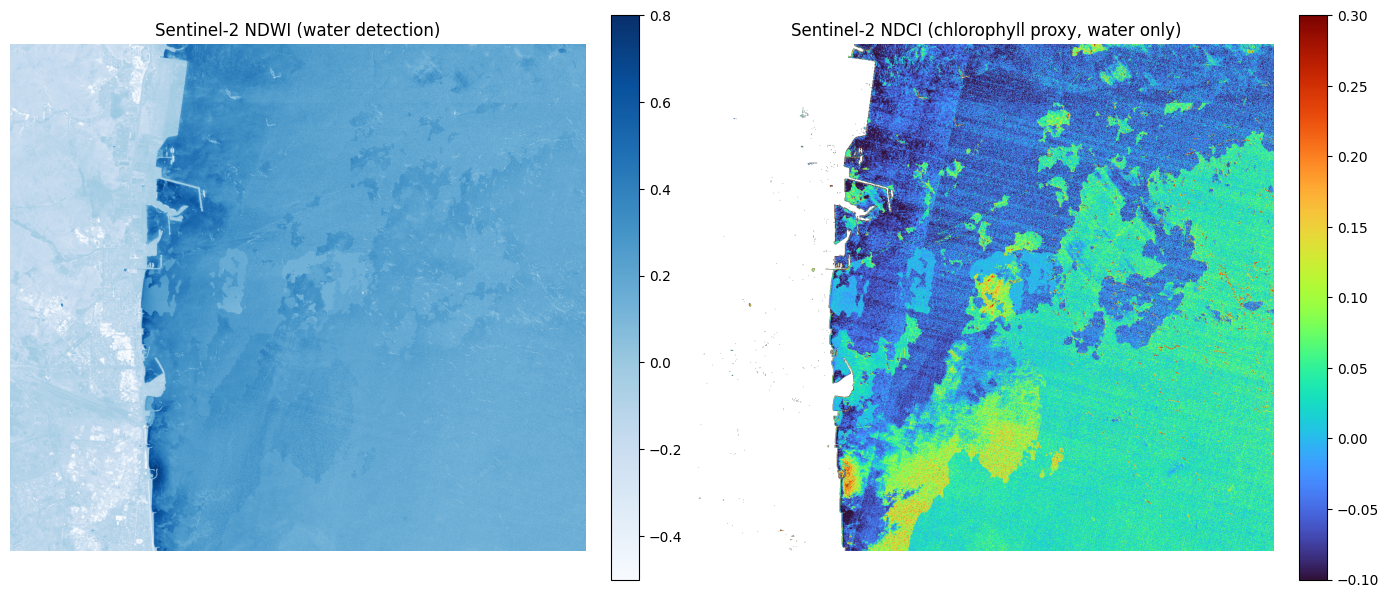

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
im = ax[0].imshow(ndwi_s2, cmap="Blues", vmin=-0.5, vmax=0.8); ax[0].set_title("Sentinel-2 NDWI (water detection)"); ax[0].axis("off")
plt.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)
im = ax[1].imshow(ndci_s2, cmap="turbo", vmin=-0.1, vmax=0.3); ax[1].set_title("Sentinel-2 NDCI (chlorophyll proxy, water only)"); ax[1].axis("off")
plt.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

## 3️⃣ Planet Tanager Hyperspectral Layer
- Scenes from `coastal-water-bodies`; we automatically prefer a scene that **intersects the AOI**.
- Bands used: 560 (Green), 665 (Red), 708 (Red-Edge), 800/860 (NIR).
- Noise filter: remove 1350–1450 nm, 1800–1950 nm, and > 2450 nm.

In [14]:
BASE = "https://www.planet.com/data/stac/tanager-core-imagery/coastal-water-bodies"

item_ids = [
    "20250223_165546_32_4001",
    "20250225_153627_16_4001",
    "20250302_030003_92_4001",
    "20250311_061550_53_4001",
    "20250406_170447_47_4001",
]

def fetch_item(iid):
    r = requests.get(f"{BASE}/{iid}/{iid}.json", timeout=60)
    r.raise_for_status()
    return r.json()

# Optional helper: scan the collection for scenes that intersect the AOI (not run by default)
def find_scenes_over_aoi(max_items=80):
    col_url = f"{BASE}/collection.json"
    col = requests.get(col_url, timeout=60).json()
    links = [l for l in col.get("links", []) if l.get("rel") == "item"][:max_items]
    hits = []
    for l in links:
        it = requests.get(urljoin(col_url, l["href"]), timeout=60).json()
        if box(*it["bbox"]).intersects(box(*bbox)):
            hits.append(it["id"])
    return hits
# print(find_scenes_over_aoi())   # uncomment, then put the returned IDs in item_ids

tanager_items = [fetch_item(i) for i in item_ids]
aoi_geom = box(*bbox)
for it in tanager_items:
    hit = box(*it["bbox"]).intersects(aoi_geom)
    print(it["id"], it["properties"]["datetime"], [round(v, 2) for v in it["bbox"]], "| intersects AOI:", hit)

hits = [it for it in tanager_items if box(*it["bbox"]).intersects(aoi_geom)]
tanager_in_aoi = len(hits) > 0
item = hits[0] if tanager_in_aoi else tanager_items[0]
if not tanager_in_aoi:
    print("\n⚠️ None of the Tanager scenes overlap the AOI. Using", item["id"], "for the spectral demo only;")
    print("   it will NOT be fused into the AOI alert. Use find_scenes_over_aoi() or move the AOI.")
print("\nSelected Tanager scene:", item["id"], item["properties"]["datetime"])

20250223_165546_32_4001 2025-02-23T16:55:46.321891Z [-88.56, 13.14, -88.35, 13.32] | intersects AOI: False
20250225_153627_16_4001 2025-02-25T15:36:27.165094Z [-70.33, 11.57, -70.11, 11.75] | intersects AOI: False
20250302_030003_92_4001 2025-03-02T03:00:03.925880Z [117.52, 0.43, 117.74, 0.66] | intersects AOI: False
20250311_061550_53_4001 2025-03-11T06:15:50.531984Z [72.53, 21.75, 72.76, 21.96] | intersects AOI: False
20250406_170447_47_4001 2025-04-06T17:04:47.473612Z [-91.49, -0.44, -91.27, -0.2] | intersects AOI: False

⚠️ None of the Tanager scenes overlap the AOI. Using 20250223_165546_32_4001 for the spectral demo only;
   it will NOT be fused into the AOI alert. Use find_scenes_over_aoi() or move the AOI.

Selected Tanager scene: 20250223_165546_32_4001 2025-02-23T16:55:46.321891Z


In [15]:
sr_key = "ortho_sr_hdf5" if "ortho_sr_hdf5" in item["assets"] else "basic_sr_hdf5"
sr_url = item["assets"][sr_key]["href"]
local_path = os.path.basename(sr_url)
print("Using SR asset:", sr_key, "\n", sr_url)

if not os.path.exists(local_path):
    print("Downloading (1-5 GB, be patient)...")
    done = 0
    with requests.get(sr_url, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(local_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk); done += len(chunk)
                    if total and (done // (1024 * 1024)) % 200 == 0:
                        print(f"  {done/total*100:.0f}%", end="\r")
    print("Saved to:", local_path)
else:
    print("File already exists:", local_path)

Using SR asset: ortho_sr_hdf5 
 https://storage.googleapis.com/open-cogs/planet-stac/tanager1-release2-core-imagery/ortho_sr_hdf5/20250223_165546_32_4001_ortho_sr_hdf5.h5
Saved to: 20250223_165546_32_4001_ortho_sr_hdf5.h5


In [16]:
root = "HDFEOS/GRIDS/HYP/Data Fields"

with h5py.File(local_path, "r") as f:
    cloud  = f[f"{root}/beta_cloud_mask"][:]
    nodata = f[f"{root}/nodata_pixels"][:]
    cirrus = f[f"{root}/beta_cirrus_mask"][:]
    sr_shape = f[f"{root}/surface_reflectance"].shape

valid = (nodata == 0) & (cloud == 0) & (cirrus == 0)
print(f"Valid {valid.mean()*100:.1f}% | Cloud {(cloud!=0).mean()*100:.1f}% | Cirrus {(cirrus!=0).mean()*100:.1f}% | NoData {(nodata!=0).mean()*100:.1f}%")

# Wavelengths from STAC metadata (micrometers -> nanometers)
asset = item["assets"][sr_key]
bands_meta = asset.get("bands") or asset.get("eo:bands") or []
wl = [b.get("eo:center_wavelength", b.get("center_wavelength")) for b in bands_meta]
wl = [w for w in wl if w is not None]
wavelengths_nm = np.array(wl, dtype=float)
if wavelengths_nm.size and wavelengths_nm.max() < 10:
    wavelengths_nm *= 1000.0
print("Cube shape:", sr_shape, "| wavelengths:", len(wavelengths_nm))
assert sr_shape[0] == len(wavelengths_nm), "Band count != wavelength count - inspect asset metadata"

def nearest_band_idx(wls, target):
    return int(np.argmin(np.abs(wls - target)))

def pick(target):
    i = nearest_band_idx(wavelengths_nm, target)
    print(f"Target {target} nm -> band {i} ({wavelengths_nm[i]:.2f} nm)")
    return i

b560, b665, b708, b800, b860 = [pick(t) for t in (560, 665, 708, 800, 860)]

Valid 72.2% | Cloud 0.0% | Cirrus 0.0% | NoData 27.8%
Cube shape: (426, 655, 785) | wavelengths: 426
Target 560 nm -> band 37 (560.83 nm)
Target 665 nm -> band 58 (665.87 nm)
Target 708 nm -> band 66 (705.92 nm)
Target 800 nm -> band 85 (801.12 nm)
Target 860 nm -> band 97 (861.26 nm)


In [17]:
# Read only the 5 required bands (not the full 426-band cube)
with h5py.File(local_path, "r") as f:
    sr = f[f"{root}/surface_reflectance"]
    R560, R665, R708, R800, R860 = [sr[i, :, :].astype("float32") for i in (b560, b665, b708, b800, b860)]

for a in (R560, R665, R708, R800, R860):
    a[~valid] = np.nan

def nd(a, b):
    return (a - b) / (a + b + 1e-6)

NDWI_t = nd(R560, R860)            # water
NDCI_t = nd(R708, R665)            # chlorophyll / HAB proxy
NDVI_t = nd(R800, R665)            # coastal vegetation (context)
TURB_t = nd(R665, R560)            # turbidity proxy

water_t = valid & (NDWI_t > 0.2)
NDCI_w = np.where(water_t, NDCI_t, np.nan)
assert water_t.sum() > 0, "No water pixels in this Tanager scene"

summarize_index("Tanager NDWI", NDWI_t)
summarize_index("Tanager NDCI (water only)", NDCI_w)
summarize_index("Tanager Turbidity proxy (water only)", np.where(water_t, TURB_t, np.nan))

Tanager NDWI:
  min   = -0.8466
  max   = 0.6319
  mean  = -0.3734
  std   = 0.4165

Tanager NDCI (water only):
  min   = -0.1763
  max   = 0.4720
  mean  = 0.0006
  std   = 0.0320

Tanager Turbidity proxy (water only):
  min   = -0.7137
  max   = -0.0232
  mean  = -0.2235
  std   = 0.0464



NDCI water: median=-0.003, p99=0.101 | clean px=42264, suspect px=846


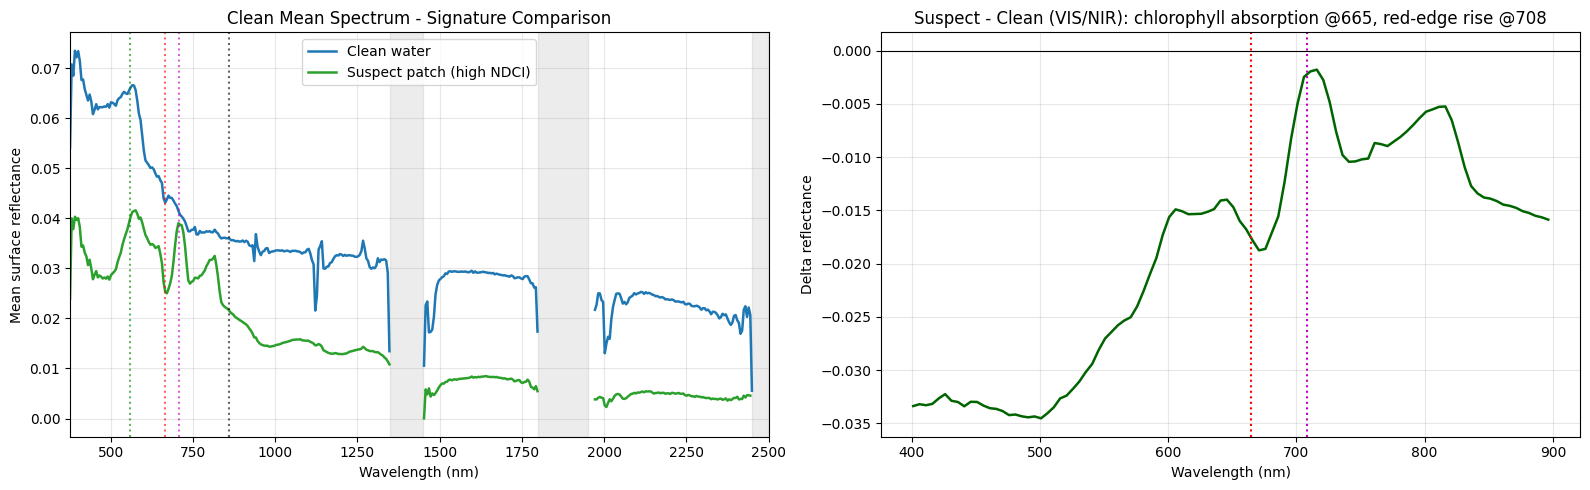

In [18]:
# ---- Clean spectrum: remove water-vapor bands and the noisy SWIR edge ----
def is_water_vapor_band(w):
    return (1350 <= w <= 1450) or (1800 <= w <= 1950)

SWIR_EDGE_NM = 2450
def is_bad_band(w):
    return is_water_vapor_band(w) or w > SWIR_EDGE_NM

bad_bands = np.array([is_bad_band(w) for w in wavelengths_nm])

# Clean water = lower half of NDCI | Suspect patch = top 1% of NDCI (relative, per scene)
p50 = np.nanpercentile(NDCI_w, 50)
p99 = np.nanpercentile(NDCI_w, 99)
clean_mask   = water_t & (NDCI_t <= p50)
suspect_mask = water_t & (NDCI_t >= p99)
print(f"NDCI water: median={p50:.3f}, p99={p99:.3f} | clean px={clean_mask.sum()}, suspect px={suspect_mask.sum()}")

STRIDE = 3
with h5py.File(local_path, "r") as f:
    cube = f[f"{root}/surface_reflectance"][:, ::STRIDE, ::STRIDE].astype("float32")

cube[bad_bands] = np.nan     # keep band axis so plot shows gaps
cube[cube < 0] = np.nan

def mean_spec(mask):
    m = mask[::STRIDE, ::STRIDE]
    if m.sum() == 0:
        return np.full(cube.shape[0], np.nan)
    return np.nanmean(cube[:, m], axis=1)

spec_clean   = mean_spec(clean_mask)
spec_suspect = mean_spec(suspect_mask)

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].plot(wavelengths_nm, spec_clean,   lw=1.8, color="tab:blue", label="Clean water")
ax[0].plot(wavelengths_nm, spec_suspect, lw=1.8, color="tab:green", label="Suspect patch (high NDCI)")
for lo, hi in [(1350, 1450), (1800, 1950), (2450, wavelengths_nm.max())]:
    ax[0].axvspan(lo, hi, color="grey", alpha=0.15)
for t, c in [(560, "g"), (665, "r"), (708, "m"), (860, "k")]:
    ax[0].axvline(t, color=c, ls=":", alpha=0.6)
ax[0].set_xlim(wavelengths_nm.min(), 2500)
ax[0].set_xlabel("Wavelength (nm)"); ax[0].set_ylabel("Mean surface reflectance")
ax[0].set_title("Clean Mean Spectrum - Signature Comparison"); ax[0].grid(alpha=0.3); ax[0].legend()

vis = (wavelengths_nm >= 400) & (wavelengths_nm <= 900)
ax[1].plot(wavelengths_nm[vis], (spec_suspect - spec_clean)[vis], color="darkgreen", lw=1.8)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].axvline(665, color="r", ls=":"); ax[1].axvline(708, color="m", ls=":")
ax[1].set_title("Suspect - Clean (VIS/NIR): chlorophyll absorption @665, red-edge rise @708")
ax[1].set_xlabel("Wavelength (nm)"); ax[1].set_ylabel("Delta reflectance"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4️⃣ Fusion Layer & Interactive NDCI Map (Pitch output #1)
`ndci_array` = water-masked NDCI from Sentinel-2 over the AOI, plus Tanager NDCI **only if** the Tanager scene intersects the AOI.

Fusion sources: Sentinel-2 only (Tanager scene outside AOI)
Saved standalone map: titan_edge_hab_map.html (open in any browser for the pitch)



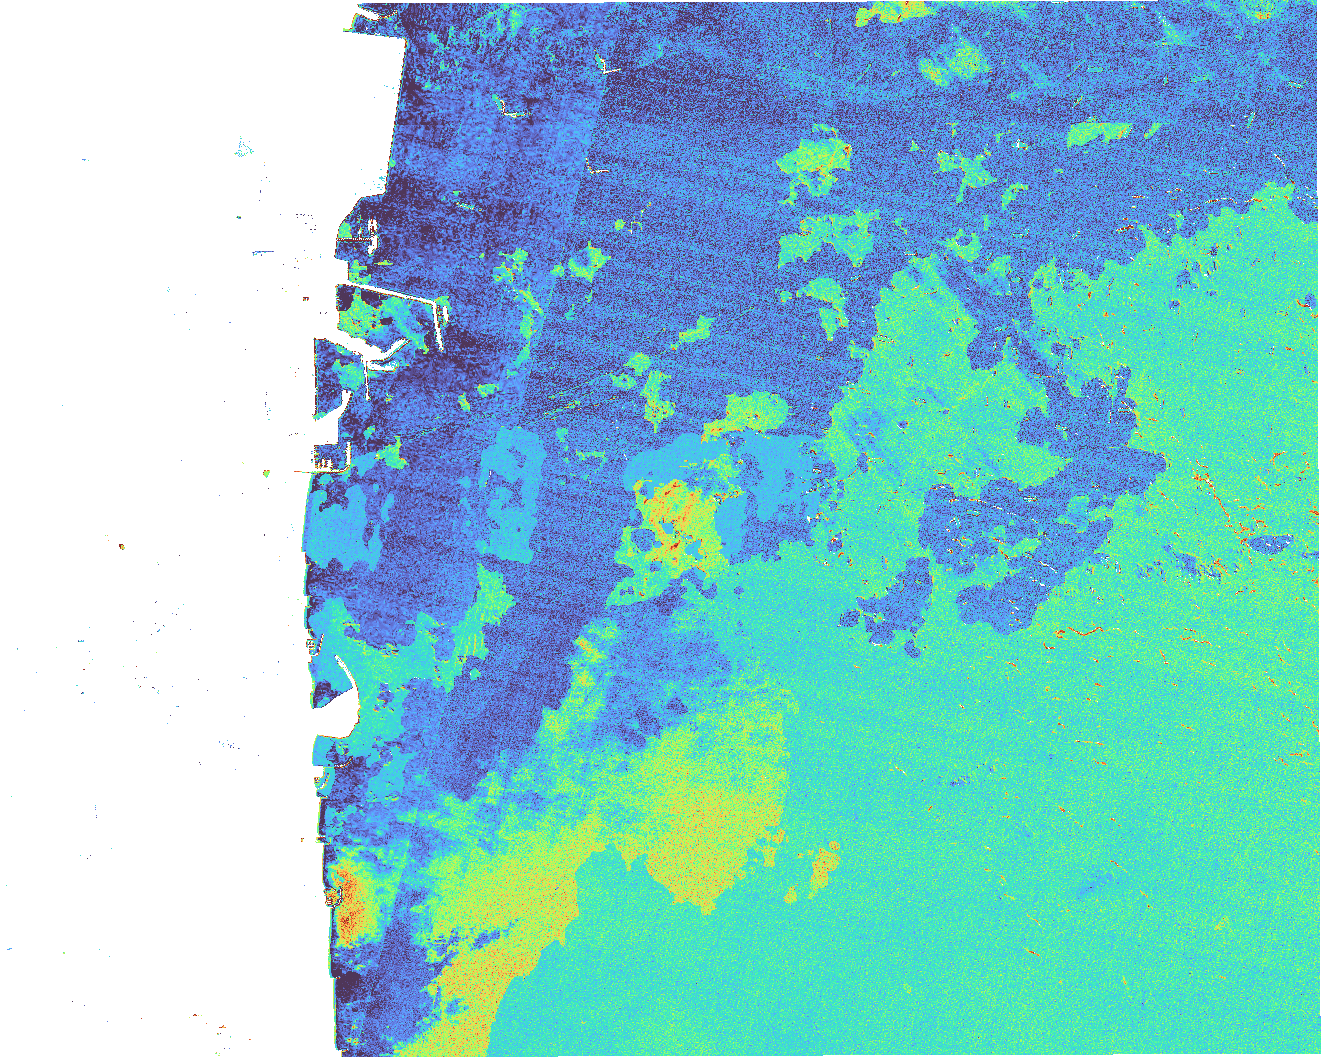

In [19]:
ndci_array = ndci_s2.copy()
if tanager_in_aoi:
    ndci_array = np.concatenate([ndci_s2.ravel(), NDCI_w.ravel()])
print("Fusion sources:", "Sentinel-2 + Tanager" if tanager_in_aoi else "Sentinel-2 only (Tanager scene outside AOI)")

# ---- Sentinel-2 NDCI to lat/lon for web mapping ----
ndci_ll = ndci_da.rio.reproject("EPSG:4326", nodata=np.nan)
arr = ndci_ll.values.astype("float32")
ys, xs = ndci_ll.y.values, ndci_ll.x.values
if ys[0] < ys[-1]:
    arr = arr[::-1]; ys = ys[::-1]
minx, miny, maxx, maxy = ndci_ll.rio.bounds()

VMIN, VMAX, CMAP = -0.1, 0.3, "turbo"
def to_rgba(a, vmin=VMIN, vmax=VMAX, cmap=CMAP):
    norm = np.clip((a - vmin) / (vmax - vmin), 0, 1)
    rgba = plt.get_cmap(cmap)(np.nan_to_num(norm))
    rgba[..., 3] = np.where(np.isfinite(a), 0.85, 0.0)
    return (rgba * 255).astype(np.uint8)

m = leafmap.Map(center=[(bbox[1] + bbox[3]) / 2, (bbox[0] + bbox[2]) / 2], zoom=10)
m.add_basemap("SATELLITE")

folium.raster_layers.ImageOverlay(
    image=to_rgba(arr), bounds=[[miny, minx], [maxy, maxx]],
    origin="upper", name="Sentinel-2 NDCI (water)", opacity=1.0,
).add_to(m)

if tanager_in_aoi:
    tb = item["bbox"]   # approximate placement (scene is north-up ortho; bbox used as bounds)
    folium.raster_layers.ImageOverlay(
        image=to_rgba(NDCI_w), bounds=[[tb[1], tb[0]], [tb[3], tb[2]]],
        origin="upper", name="Tanager NDCI (approx. geolocation)", opacity=1.0,
    ).add_to(m)

folium.Rectangle([[bbox[1], bbox[0]], [bbox[3], bbox[2]]], color="red", weight=2, fill=False, name="AOI").add_to(m)
tb = item["bbox"]
folium.Rectangle([[tb[1], tb[0]], [tb[3], tb[2]]], color="cyan", weight=2, fill=False,
                 name="Tanager footprint").add_to(m)

folium.Marker(INTAKE_LATLON, tooltip="Desalination intake (illustrative)",
              icon=folium.Icon(color="blue", icon="tint", prefix="fa")).add_to(m)

# Hotspots: top-N S2 NDCI pixels (red if above threshold, orange otherwise)
valid_idx = np.argwhere(np.isfinite(arr))
if len(valid_idx):
    vals = arr[valid_idx[:, 0], valid_idx[:, 1]]
    order = np.argsort(vals)[::-1][:15]
    for k in order:
        r, c = valid_idx[k]
        v = float(vals[k])
        folium.CircleMarker([float(ys[r]), float(xs[c])], radius=5,
                            color="red" if v > HAB_THRESHOLD else "orange", fill=True,
                            tooltip=f"NDCI = {v:.3f}").add_to(m)

cm = bcm.LinearColormap([mcolors.to_hex(plt.get_cmap(CMAP)(v)) for v in np.linspace(0, 1, 8)],
                        vmin=VMIN, vmax=VMAX, caption="NDCI (chlorophyll proxy)")
cm.add_to(m)
folium.LayerControl().add_to(m)

m.save("titan_edge_hab_map.html")
print("Saved standalone map: titan_edge_hab_map.html (open in any browser for the pitch)")
m

## 5️⃣ Titan-Edge Decision & Trigger Kernel (Pitch output #3)

In [20]:
# Titan-Edge Decision & Trigger Kernel
max_ndci = np.nanmax(ndci_array)

print(f"📊 Maximum NDCI (Chlorophyll Proxy): {max_ndci:.4f}")

if max_ndci > 0.25:  # HAB / Algae Bloom Threshold
    print("🚨 [TITAN-ALERT]: Harmful Algal Bloom anomaly detected near critical intake!")
    print("🛰️ Data Source: Planet Tanager & Sentinel-2 Fusion Engine")
    print("🚁 [TITAN-AIR TRIGGER]: Autonomous Drone 'Falcon Eye' dispatched for close-range verification.")
    print("🛡️ [TITAN-POWER ACTION]: Transmitting Low-Power Signal to secure desalination intake filters.")
else:
    print("✅ [TITAN-EDGE STATUS]: Marine ecosystem normal. Monitoring system in low-power standby.")

📊 Maximum NDCI (Chlorophyll Proxy): 0.7874
🚨 [TITAN-ALERT]: Harmful Algal Bloom anomaly detected near critical intake!
🛰️ Data Source: Planet Tanager & Sentinel-2 Fusion Engine
🚁 [TITAN-AIR TRIGGER]: Autonomous Drone 'Falcon Eye' dispatched for close-range verification.
🛡️ [TITAN-POWER ACTION]: Transmitting Low-Power Signal to secure desalination intake filters.


In [21]:
# Supporting evidence + machine-readable event log (what a dashboard / MQTT / REST alert would carry)
finite = ndci_array[np.isfinite(ndci_array)]
event = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "aoi": AOI_NAME, "bbox": bbox, "intake": INTAKE_LATLON,
    "sources": ["Sentinel-2 L2A"] + (["Planet Tanager"] if tanager_in_aoi else []),
    "ndci_max": float(np.nanmax(finite)),
    "ndci_p99": float(np.nanpercentile(finite, 99)),
    "pct_water_px_above_threshold": float((finite > HAB_THRESHOLD).mean() * 100),
    "threshold": HAB_THRESHOLD,
    "status": "ALERT" if np.nanmax(finite) > HAB_THRESHOLD else "NORMAL",
}
print(json.dumps(event, indent=2, ensure_ascii=False))
# In production: requests.post(TITAN_EDGE_WEBHOOK, json=event)  # -> Falcon Eye dispatch / intake-protection controller

{
  "timestamp_utc": "2026-10-08T08:03:55.755481+00:00",
  "aoi": "Fujairah - Gulf of Oman (desalination intake zone)",
  "bbox": [
    56.3,
    25.05,
    56.55,
    25.25
  ],
  "intake": [
    25.17,
    56.36
  ],
  "sources": [
    "Sentinel-2 L2A"
  ],
  "ndci_max": 0.7873638272285461,
  "ndci_p99": 0.1643143594264984,
  "pct_water_px_above_threshold": 0.1962062353999058,
  "threshold": 0.25,
  "status": "ALERT"
}


## 📊 Before You Submit
- **Validation:** compare NDCI/Chl-a against in-situ samples or a documented HAB event (precision/recall, RMSE); calibrate the 0.25 threshold on that data.
- **Robustness:** max-pixel triggers are noise-sensitive; consider a minimum cluster size and persistence across 2+ acquisitions before dispatching.
- **Delivery:** dashboard map (`titan_edge_hab_map.html`) + JSON alert event to the Titan-Edge controller.